# Predicting survival of coronary artery disease patients

Exploration of `data/classification_bonus_practice_data.csv`, and the reasoning
behind every cleaning and feature decision that `src/data_preparation.py` then
applies.

This notebook is written in the order the work actually happened, including the
wrong turn, because the wrong turn is what found the most important thing in
the dataset.

1. First look, and the two label styles running through the file
2. A first model, trained the ordinary way
3. That score cannot be right. Finding out why
4. Using the patient groups as a microscope
5. Two columns that are really yes/no flags
6. Height, Weight and BMI
7. The gaps in Creatinine
8. What predicts survival, measured per patient
9. Decisions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

raw = pd.read_csv("data/classification_bonus_practice_data.csv")
raw.shape

(15000, 16)

## 1. First look

In [2]:
raw.head()

,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
0,TIG1GE,0,Male,Yes,Normal,50,Low,141,0.7,266000.0,185,105,12.3,180,93,green
1,VXUCV9,1,Male,No,Normal,75,Low,134,2.5,224000.0,99,162,13.0,140,47,black
2,AFH4F1,1,Female,No,Pre-diabetes,80,Low,135,1.3,192000.0,776,179,12.4,150,61,white
3,ZK6PAC,0,Male,No,Normal,-60,Low,136,0.9,228000.0,2261,136,15.3,130,48,yellow
4,6CVBRT,0,Female,No,Normal,70,Low,141,0.9,358000.0,1202,171,13.3,177,64,blue


In [3]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique": raw.nunique(),
})

,dtype,missing,unique
ID,str,0,14042
Survive,str,0,4
Gender,str,0,2
Smoke,str,0,4
Diabetes,str,0,3
Age,int64,0,87
Ejection Fraction,str,0,5
Sodium,int64,0,27
Creatinine,float64,499,40
Platelets,float64,0,176


Only `Creatinine` has gaps, 499 of them. No row is an exact duplicate of
another. `ID` is not unique though, which is the first thing worth chasing.

In [4]:
print("exact duplicate rows:", raw.duplicated().sum())
print("rows:", len(raw), " unique IDs:", raw["ID"].nunique())
print(raw["ID"].value_counts().value_counts().sort_index().rename("how many IDs").to_frame().T)

exact duplicate rows: 0
rows: 15000  unique IDs: 14042
count             1    2   3  4
how many IDs  13157  816  65  4


885 codes are used by more than one row. Looking at a few of them, the rows
sharing a code have nothing else in common, different sex, different age,
different bloodwork. They are collisions in a short random code, not the same
patient twice. One value also came out of a spreadsheet as scientific notation.

In [5]:
repeats = raw["ID"][raw["ID"].duplicated(keep=False)].unique()[:3]
display(raw[raw["ID"].isin(repeats)].sort_values("ID"))
display(raw[raw["ID"].str.len() != 6])

,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
26,DT5QJP,0,Female,No,Normal,60,Low,145,0.9,127000.0,582,133,9.4,178,97,yellow
2297,DT5QJP,0,Male,Yes,Normal,70,Low,138,2.7,223000.0,75,54,9.6,132,60,yellow
23,RXITR4,0,Male,No,Normal,85,Low,134,NaN,235000.0,910,41,11.8,160,71,yellow
9395,RXITR4,0,Male,Yes,Normal,53,Low,137,1.1,305000.0,582,62,9.3,188,68,black
9,VBTJA1,1,Female,No,Normal,60,Low,127,1.7,62000.0,166,59,12.3,156,47,black
727,VBTJA1,0,Male,Yes,Normal,65,Low,145,1.1,194000.0,118,91,12.6,167,56,blue


,ID,Survive,Gender,Smoke,Diabetes,Age,Ejection Fraction,Sodium,Creatinine,Platelets,Creatine phosphokinase,Blood Pressure,Hemoglobin,Height,Weight,Favorite color
9596,8.46E+65,Yes,Female,NO,Diabetes,65,Low,116,2.7,327000.0,160,66,11.2,139,76,green


So `ID` identifies nothing reliably. It is dropped.

### The categorical columns are typed two ways

`Survive`, `Smoke` and `Ejection Fraction` each carry two encodings of the same
information, and `Diabetes` carries two labels for one condition.

In [6]:
for c in ["Survive", "Gender", "Smoke", "Diabetes", "Ejection Fraction", "Favorite color"]:
    print(c)
    print(raw[c].value_counts().to_string())
    print()

Survive
Survive
0      9581
1      4552
No      604
Yes     263

Gender
Gender
Male      9757
Female    5243

Smoke
Smoke
No     9710
Yes    4707
NO      399
YES     184

Diabetes
Diabetes
Normal          8789
Pre-diabetes    3124
Diabetes        3087

Ejection Fraction
Ejection Fraction
Low       12734
Normal     1658
L           482
N            66
High         60

Favorite color
Favorite color
blue      2532
yellow    2530
green     2507
red       2491
white     2476
black     2464



Merging the short forms only makes sense if the two spellings behave the same.
They do: `L` survives at 0.346 against `Low` at 0.339, `N` at 0.152 against
`Normal` at 0.194, `NO` at 0.356 against `No` at 0.324. The differences are
inside the noise of the smaller group.

In [7]:
df = raw.copy()
df["Survive"] = df["Survive"].map({"0": 0, "1": 1, "No": 0, "Yes": 1})
df["Age"] = df["Age"].abs()

for c in ["Survive", "Smoke", "Ejection Fraction"]:
    col = raw[c]
    print(c)
    print(df.groupby(col.values, observed=True)["Survive"].agg(["mean", "count"]).to_string())
    print()

Survive
     mean  count
0     0.0   9581
1     1.0   4552
No    0.0    604
Yes   1.0    263

Smoke
         mean  count
NO   0.355890    399
No   0.323687   9710
YES  0.298913    184
Yes  0.313363   4707

Ejection Fraction
            mean  count
High    0.000000     60
L       0.346473    482
Low     0.339014  12734
N       0.151515     66
Normal  0.193607   1658



### Negative ages

430 ages are negative. Their absolute values sit on the same distribution as
the positive ones, so they are sign errors rather than a different kind of
patient. `abs()` recovers them.

       negative, sign flipped  positive
count                  430.00  14570.00
mean                    60.03     60.90
std                     11.29     11.88
min                     40.00     40.00
25%                     50.00     51.00
50%                     60.00     60.00
75%                     68.00     70.00
max                     95.00     95.00


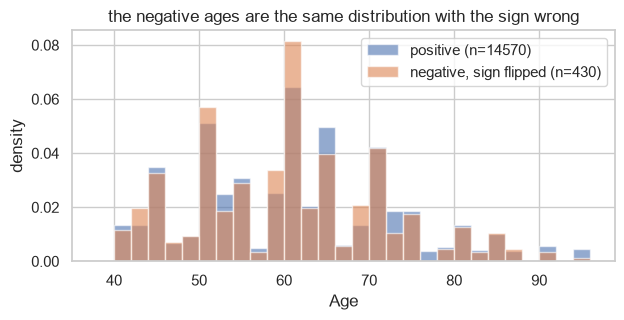

In [8]:
neg = raw.loc[raw["Age"] < 0, "Age"].abs()
pos = raw.loc[raw["Age"] > 0, "Age"]
print(pd.DataFrame({"negative, sign flipped": neg.describe(), "positive": pos.describe()}).round(2))

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(38, 98, 2)
ax.hist(pos, bins=bins, alpha=0.6, density=True, label=f"positive (n={len(pos)})")
ax.hist(neg, bins=bins, alpha=0.6, density=True, label=f"negative, sign flipped (n={len(neg)})")
ax.set_xlabel("Age"); ax.set_ylabel("density"); ax.legend()
ax.set_title("the negative ages are the same distribution with the sign wrong")
plt.show()

### An obvious decoy

The brief warns that some features are synthetic. `Favorite color` is the
candidate: uniform over six values and flat against survival.

In [9]:
print(df.groupby("Favorite color")["Survive"].agg(["mean", "count"]).sort_values("mean").to_string())

                    mean  count
Favorite color                 
yellow          0.304743   2530
white           0.316640   2476
blue            0.317930   2532
green           0.323095   2507
black           0.325893   2464
red             0.338017   2491


### The target

Imbalanced, roughly two thirds did not survive. Worth remembering when reading
accuracy later: a model that says "did not survive" to everyone is right 67.9%
of the time.

In [10]:
df["Survive"].value_counts().rename({0: "did not survive", 1: "survived"}).to_frame("rows").assign(
    share=lambda d: (d["rows"] / len(df)).round(3)
)

,rows,share
Survive,,
did not survive,10185,0.679
survived,4815,0.321


## 2. A first model, trained the ordinary way

Nothing above suggests anything unusual. So: standardise the labels, drop `ID`
and `Favorite color`, one hot encode, impute `Creatinine` with the median, and
split 80/20 stratified on `Survive` so both sides carry the same class balance.

Four models plus a majority-class baseline.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

first = df.copy()
first["Smoke"] = first["Smoke"].str.capitalize()
first["Ejection Fraction"] = first["Ejection Fraction"].replace({"L": "Low", "N": "Normal"})
first = first.drop(columns=["ID", "Favorite color"])

y = first["Survive"]
X = first.drop(columns="Survive")
num = X.select_dtypes("number").columns.tolist()
cat = [c for c in X.columns if c not in num]

prep = ColumnTransformer([
    ("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
])

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"train {len(X_tr)} rows, test {len(X_te)} rows")
print(f"survived: {y_tr.mean():.1%} of train, {y_te.mean():.1%} of test")

train 12000 rows, test 3000 rows
survived: 32.1% of train, 32.1% of test


In [12]:
models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)]).fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    prob = pipe.predict_proba(X_te)[:, 1]
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred, zero_division=0),
        "f1": f1_score(y_te, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_te, prob),
    })

pd.DataFrame(rows).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline (majority),0.679,0.000,0.000,0.000,0.500
Logistic Regression,0.827,0.768,0.659,0.709,0.872
Decision Tree,0.993,0.992,0.988,0.990,0.992
Random Forest,0.999,1.000,0.998,0.999,1.000
Gradient Boosting,1.000,1.000,1.000,1.000,1.000


## 3. That score cannot be right

The three tree models land between 0.992 and 1.000 AUC, and Gradient Boosting
is flawless on every single metric. Nothing about predicting survival from
bloodwork is that easy, and no clean dataset produces a perfect classifier.

The shape of the failure is the clue. Logistic regression gets 0.872, which is
a believable score. The trees get essentially 1.000. So whatever is going on is
something trees can do and a linear model cannot, and the obvious candidate is
**memorising individual records**. A tree can keep splitting until each leaf
holds one specific patient. A linear model has one coefficient per feature and
nowhere to store 15000 individuals.

That only wins if the test set contains patients the model already saw. Which
would mean the rows are not 15000 different people.

### Looking for repeats

The distinct-value counts are the giveaway, but only for the right columns.

In [13]:
counts = pd.DataFrame({
    "distinct values": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})
counts.loc[["Age", "Sodium", "Creatinine", "Platelets", "Creatine phosphokinase",
            "Hemoglobin", "Blood Pressure", "Height", "Weight"]]

,distinct values,min,max
Age,46,40.0,95.0
Sodium,27,113.0,148.0
Creatinine,40,0.5,9.4
Platelets,176,25100.0,850000.0
Creatine phosphokinase,208,23.0,7861.0
Hemoglobin,86,9.0,17.5
Blood Pressure,139,40.0,179.0
Height,60,130.0,189.0
Weight,123,19.0,141.0


`Age` with 46 values over 40-95 and `Sodium` with 27 over 113-148 are not
suspicious at all: those are whole numbers in a narrow range, so they have to
repeat.

`Platelets` is the one that matters. It runs from 25,100 to 850,000, and 15000
real measurements should land on thousands of different values. It lands on
176. `Creatine phosphokinase` gives 208 across a range of 23 to 7,861.

### Building a fingerprint

If rows repeat people, then pasting together the columns that belong to a
person should collapse 15000 rows into far fewer. Adding one column at a time
shows where it settles.

In [14]:
def make_key(frame, cols):
    key = None
    for c in cols:
        text = frame[c].map(lambda v: str(v))
        key = text if key is None else key + "|" + text
    return key

KEY_COLS = ["Age", "Sodium", "Platelets", "Creatine phosphokinase"]

for i in range(1, len(KEY_COLS) + 1):
    cols = KEY_COLS[:i]
    key = make_key(df, cols)
    mixed = (df.assign(k=key).groupby("k")["Survive"].nunique() > 1).sum()
    print(f"{' + '.join(cols):<52} {key.nunique():5d} groups, "
          f"{mixed:3d} holding both outcomes")

Age                                                     46 groups,  25 holding both outcomes
Age + Sodium                                           197 groups,  30 holding both outcomes
Age + Sodium + Platelets                               294 groups,   3 holding both outcomes
Age + Sodium + Platelets + Creatine phosphokinase      297 groups,   0 holding both outcomes


Four columns, 297 groups, and not one of them contains both a survivor and a
non-survivor. 46 x 27 x 176 x 208 is about 45 million possible combinations;
15000 genuinely different patients dropped into 45 million slots would almost
never collide. 297 is not a coincidence.

distinct patients: 297
rows per patient: min 32  median 50  max 109


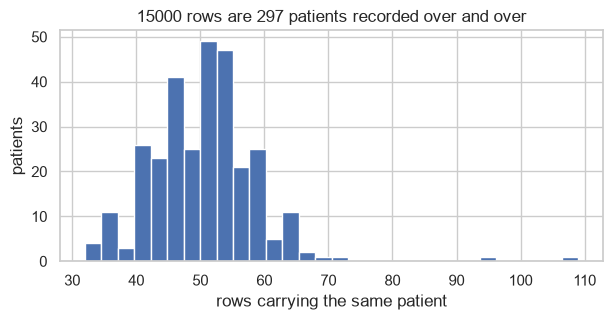

In [15]:
df["patient_key"] = make_key(df, KEY_COLS)

sizes = df["patient_key"].value_counts()
print("distinct patients:", len(sizes))
print("rows per patient: min", sizes.min(), " median", int(sizes.median()), " max", sizes.max())

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(sizes, bins=30)
ax.set_xlabel("rows carrying the same patient"); ax.set_ylabel("patients")
ax.set_title("15000 rows are 297 patients recorded over and over")
plt.show()

### Confirming the leak

If that is right, the split from section 2 put copies of the same patient on
both sides.

In [16]:
key_tr = df.loc[X_tr.index, "patient_key"]
key_te = df.loc[X_te.index, "patient_key"]

print(f"test rows whose patient also appears in training: {key_te.isin(set(key_tr)).mean():.1%}")
print(f"test patients: {key_te.nunique()}, already seen in training: "
      f"{key_te[key_te.isin(set(key_tr))].nunique()}")

test rows whose patient also appears in training: 100.0%
test patients: 297, already seen in training: 297


Every one. There was never an unseen patient to predict. Here is a single test
row next to its copies in the training set.

In [17]:
row = X_te.index[0]
fingerprint = key_te.loc[row]
twins = key_tr[key_tr == fingerprint].index
print(f"test row {row}, fingerprint {fingerprint}")
print(f"the same patient appears {len(twins)} times in the training set\n")

show_cols = ["Age", "Sodium", "Platelets", "Creatine phosphokinase",
             "Creatinine", "Hemoglobin", "Height", "Weight", "Gender"]
show = pd.concat([X.loc[[row], show_cols], X.loc[twins[:4], show_cols]])
show.insert(0, "which set", ["TEST"] + ["train"] * 4)
show.insert(1, "Survive", [y.loc[row]] + list(y.loc[twins[:4]]))
show

test row 3210, fingerprint 60|139|204000.0|47
the same patient appears 38 times in the training set



,which set,Survive,Age,Sodium,Platelets,Creatine phosphokinase,Creatinine,Hemoglobin,Height,Weight,Gender
3210,TEST,1,60,139,204000.0,47,0.7,10.3,187,114,Male
798,train,1,60,139,204000.0,47,0.7,9.3,137,61,Male
14094,train,1,60,139,204000.0,47,0.7,11.7,153,77,Male
1928,train,1,60,139,204000.0,47,0.7,10.4,165,89,Male
1687,train,1,60,139,204000.0,47,0.7,10.6,167,91,Male


Identical bloodwork, identical outcome, only the synthetic columns move. The
tree is not predicting anything, it is looking the answer up.

**This is the most important finding in the dataset.** The effective sample
size is 297, not 15000. Every split from here on keeps a patient wholly on one
side, using `StratifiedGroupKFold`, which balances the classes *and* respects
the grouping. `src/model_training.py` reruns both ways and writes the
comparison to `results/leakage_check.csv`:

| model | AUC, random row split | AUC, patient split |
|---|---|---|
| Decision Tree | 0.9995 | 0.769 |
| Random Forest | 1.0000 | 0.868 |
| Gradient Boosting | 1.0000 | 0.848 |
| Logistic Regression | 0.876 | 0.851 |

Logistic regression barely moves, exactly as predicted: it could not memorise
patients, so it had nothing to lose.

## 4. Using the patient groups as a microscope

The grouping is not only a fix for the split. Now that rows can be tied to a
person, a new question becomes available: **does this column stay the same for
one patient, or is it redrawn on every copy?** A real attribute cannot change.
Anything that does was generated.

This one test sorts out most of the remaining columns.

In [18]:
g = df.groupby("patient_key")
pd.DataFrame({
    "mean distinct values per patient": g.nunique().mean().round(2),
}).drop(index=["Survive", "patient_key"], errors="ignore").sort_values(
    "mean distinct values per patient"
)

,mean distinct values per patient
Gender,1.00
Age,1.00
Sodium,1.00
Creatinine,1.00
Platelets,1.00
Creatine phosphokinase,1.00
Diabetes,1.42
Ejection Fraction,1.81
Smoke,1.88
Favorite color,6.00


Three groups fall out of this.

**Constant, so real:** `Age`, `Sodium`, `Platelets` and `Creatine
phosphokinase` by construction, but also `Creatinine`, `Gender`, `Smoke` and
`Ejection Fraction`, which were *not* used to build the key and come out
constant anyway. That is the check that the fingerprint is picking out patients
rather than slicing arbitrarily.

**Redrawn every row, so synthetic:** `Favorite color` takes all six values
inside every patient. `Height` takes about 34 different values per patient,
spanning the full 130-189 range. `ID` is in there too at 50 values per patient,
which is the last word on whether it identifies anybody.

**In between:** `Diabetes` averages 1.42, `Hemoglobin` and `Blood Pressure`
take about 30 values each. Those three need a closer look.

In [19]:
for c in ["Gender", "Smoke", "Ejection Fraction", "Creatinine"]:
    constant = (g[c].nunique() <= 1).mean()
    print(f"{c:<20} constant within the patient for {constant:.1%} of patients")

Gender               constant within the patient for 100.0% of patients
Smoke                constant within the patient for 12.5% of patients
Ejection Fraction    constant within the patient for 19.5% of patients
Creatinine           constant within the patient for 100.0% of patients


`Smoke` and `Ejection Fraction` look variable only because of the two label
styles. Fold those in and they are constant too.

In [20]:
df["Smoke"] = df["Smoke"].str.capitalize()
df["Ejection Fraction"] = df["Ejection Fraction"].replace({"L": "Low", "N": "Normal"})
g = df.groupby("patient_key")
for c in ["Smoke", "Ejection Fraction"]:
    print(f"{c:<20} constant within the patient for {(g[c].nunique() <= 1).mean():.1%} of patients")

Smoke                constant within the patient for 100.0% of patients
Ejection Fraction    constant within the patient for 99.7% of patients


### Favourite colour, confirmed

Section 1 showed it was flat. The microscope shows *why*: it is redrawn on
every copy, so every single patient displays all six colours.

In [21]:
print("patients showing all six colours:", (g["Favorite color"].nunique() == 6).mean())

patients showing all six colours: 1.0


Keeping it would not cost much (0.869 grouped AUC against 0.870), but a model
that never sees it can never lean on it.

### Diabetes is one condition written two ways

A patient is either `Normal` on every row, or has their rows split at random
between `Diabetes` and `Pre-diabetes`. One patient out of 297 breaks that, and
it is one of the two keys flagged below.

In [22]:
spread = df.groupby(["patient_key", "Diabetes"]).size().unstack(fill_value=0)
print(spread.head(8).to_string())
print()
mixed = (spread["Normal"] > 0) & (spread[["Diabetes", "Pre-diabetes"]].sum(axis=1) > 0)
print("patients ever labelled Normal and also diabetic:", mixed.sum())
print(spread[mixed].to_string())

Diabetes             Diabetes  Normal  Pre-diabetes
patient_key                                        
40|132|222000.0|582        27       0            29
40|136|255000.0|90          0      53             0
40|136|303000.0|478        28       0            30
40|137|255000.0|129         0      54             0
40|140|275000.0|244         0      52             0
40|141|226000.0|101         0      42             0
40|142|301000.0|624         0      40             0
41|140|374000.0|148         0      49             0

patients ever labelled Normal and also diabetic: 1
Diabetes              Diabetes  Normal  Pre-diabetes
patient_key                                         
45|137|263358.03|582        21      60            28


So the real variable is binary, and `Pre-diabetes` folds into `Diabetes`.

### Two keys are almost certainly two patients each

The exception above, and the only two keys whose blood pressure crosses the 120
line in the next section, are the same two keys. Both carry
`Platelets = 263358.03`, which is a filled-in average rather than a reading:
1245 rows share it. Most keys carrying it are still one patient, but these two
are roughly twice the size of anything else in the file.

In [23]:
odd = df[df["Platelets"] == 263358.03]
sizes = odd.groupby("patient_key").agg(rows=("Survive", "size"), survived=("Survive", "mean"))
print("rows carrying the filled-in platelet count:", len(odd), "across", len(sizes), "keys")
print("median rows per patient across the whole file:", int(df["patient_key"].value_counts().median()))
print()
print(sizes.sort_values("rows", ascending=False).head(4).to_string())

rows carrying the filled-in platelet count: 1245 across 23 keys
median rows per patient across the whole file: 50

                      rows  survived
patient_key                         
45|137|263358.03|582   109       0.0
75|137|263358.03|582    96       0.0
86|134|263358.03|582    64       1.0
80|134|263358.03|805    61       1.0


Two patients whose platelet count was filled in with the same average, and who
happen to share an age, a sodium level and a CPK reading, collapse into one
key. It does not break anything: the outcome is still constant inside each, so
the split still keeps related rows on the same side. It makes the grouping
slightly conservative, treating two patients as one, which errs in the safe
direction.

## 5. Two columns that are really yes/no flags

`Hemoglobin` and `Blood Pressure` vary inside a patient, but not freely. Each
patient's values sit in one of two disjoint bands, with nothing in between.

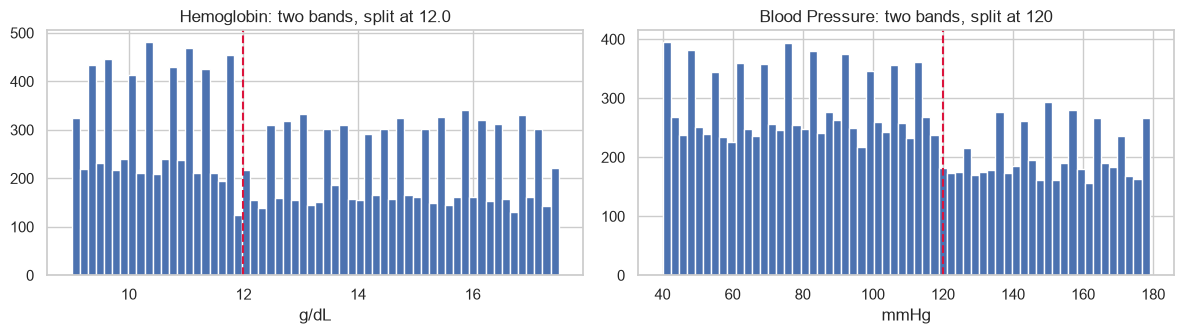

Hemoglobin values between 11.9 and 12.0: []
Blood Pressure values of exactly 120: 0


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(df["Hemoglobin"], bins=60)
axes[0].axvline(12.0, color="crimson", ls="--")
axes[0].set_title("Hemoglobin: two bands, split at 12.0"); axes[0].set_xlabel("g/dL")
axes[1].hist(df["Blood Pressure"], bins=60)
axes[1].axvline(120, color="crimson", ls="--")
axes[1].set_title("Blood Pressure: two bands, split at 120"); axes[1].set_xlabel("mmHg")
plt.tight_layout(); plt.show()

print("Hemoglobin values between 11.9 and 12.0:", sorted(v for v in df["Hemoglobin"].unique() if 11.9 < v < 12.0))
print("Blood Pressure values of exactly 120:", (df["Blood Pressure"] == 120).sum())

Within a patient the range is the width of one band, not the width of the
column. Every patient falls entirely on one side of each threshold.

In [25]:
hb = g["Hemoglobin"].agg(["min", "max"])
bp = g["Blood Pressure"].agg(["min", "max"])
print("patients entirely below Hemoglobin 12:", (hb["max"] < 12).sum())
print("patients entirely at or above 12:      ", (hb["min"] >= 12).sum())
print("patients straddling the line:          ", ((hb["min"] < 12) & (hb["max"] >= 12)).sum())
print()
print("patients entirely below Blood Pressure 120:", (bp["max"] < 120).sum())
print("patients entirely at or above 120:         ", (bp["min"] >= 120).sum())
print("patients straddling the line:              ", ((bp["min"] < 120) & (bp["max"] >= 120)).sum())

patients entirely below Hemoglobin 12: 129
patients entirely at or above 12:       168
patients straddling the line:           0

patients entirely below Blood Pressure 120: 192
patients entirely at or above 120:          103
patients straddling the line:               2


No hemoglobin reading crosses, and the only two blood pressure keys that do are
the two merged ones from the previous section. There is no reading of exactly
120 anywhere in the file: the bands are 40-119 and 121-179.

The spread inside a band is noise, the band is the signal, so both columns
become flags: `anaemia` for Hemoglobin below 12, `high_bp` for Blood Pressure
at 120 or above.

In [26]:
df["anaemia"] = (df["Hemoglobin"] < 12).astype(int)
df["high_bp"] = (df["Blood Pressure"] >= 120).astype(int)

## 6. Height, Weight and BMI

`Height` is uniform over 130-189 and redrawn on every row of a patient, so on
its own it is noise. `Weight` is not: it correlates 0.41 with survival. But the
relationship between weight and survival changes completely depending on how
tall the patient is.

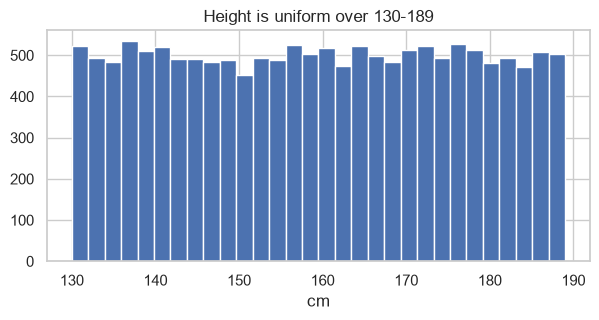

survival rate by weight, split by height
height_group    short  middle   tall
Weight                              
(18.999, 46.0]  0.107   0.043  0.005
(46.0, 60.0]    0.244   0.161  0.088
(60.0, 73.0]    0.515   0.233  0.159
(73.0, 92.0]    0.883   0.392  0.230
(92.0, 141.0]     NaN   0.835  0.521


In [27]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(df["Height"], bins=30)
ax.set_title("Height is uniform over 130-189"); ax.set_xlabel("cm")
plt.show()

df["height_group"] = pd.qcut(df["Height"], 3, labels=["short", "middle", "tall"])
weight_band = pd.qcut(df["Weight"], 5)
print("survival rate by weight, split by height")
print(pd.crosstab(weight_band, df["height_group"], values=df["Survive"], aggfunc="mean").round(3).to_string())

Reading across any row, the same weight means very different things at
different heights. Dividing by height squared removes it: the same table built
on BMI is flat across the three height groups.

In [28]:
df["bmi"] = df["Weight"] / (df["Height"] / 100) ** 2
bmi_band = pd.qcut(df["bmi"], 5)
print("survival rate by BMI, split by height")
print(pd.crosstab(bmi_band, df["height_group"], values=df["Survive"], aggfunc="mean").round(3).to_string())

survival rate by BMI, split by height
height_group      short  middle   tall
bmi                                   
(11.242, 18.935]  0.042   0.041  0.068
(18.935, 25.156]  0.219   0.232  0.228
(25.156, 30.494]  0.185   0.181  0.158
(30.494, 34.02]   0.285   0.293  0.286
(34.02, 39.796]   0.872   0.870  0.855


And the decisive check, which again only the patient grouping makes possible:
BMI is constant within a patient, even though both of the columns it is built
from vary.

In [29]:
within = pd.DataFrame({
    "spread inside one patient (sd)": g[["Height", "Weight"]].std().mean().round(2),
    "spread across everyone (sd)": df[["Height", "Weight"]].std().round(2),
})
within.loc["bmi"] = [df.groupby("patient_key")["bmi"].std().mean().round(3), round(df["bmi"].std(), 3)]
within

,spread inside one patient (sd),spread across everyone (sd)
Height,17.320,17.340
Weight,14.920,25.300
bmi,0.141,7.734


A patient's BMI varies by 0.14 across their rows against 7.73 across the
dataset. `Weight` was generated as BMI times height squared. So BMI is the real
attribute and `Height` and `Weight` are it split across two columns, the same
way `Hemoglobin` hid a yes/no flag. Both originals are dropped.

BMI is also the strongest single predictor in the dataset, and it does not move
in a straight line.

patients: 297  survived: 32.3%


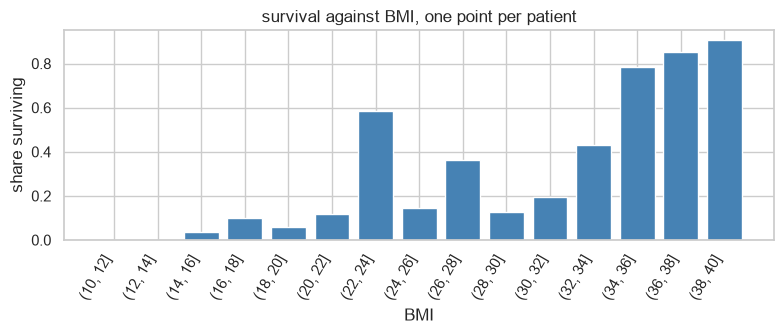

,mean,count
bmi,,
"(10, 12]",0.000000,1
"(12, 14]",0.000000,5
"(14, 16]",0.037037,27
"(16, 18]",0.100000,10
"(18, 20]",0.057143,35
"(20, 22]",0.120000,25
"(22, 24]",0.583333,12
"(24, 26]",0.142857,14
"(26, 28]",0.363636,11


In [30]:
patients = pd.DataFrame({
    "Survive": g["Survive"].first(),
    "Age": g["Age"].first(),
    "Sodium": g["Sodium"].first(),
    "Creatinine": g["Creatinine"].mean(),
    "Platelets": g["Platelets"].first(),
    "Creatine phosphokinase": g["Creatine phosphokinase"].first(),
    "bmi": g["bmi"].mean(),
    "anaemia": g["anaemia"].first(),
    "high_bp": g["high_bp"].first(),
    "Gender": g["Gender"].first(),
    "Smoke": g["Smoke"].first(),
    "Ejection Fraction": g["Ejection Fraction"].agg(lambda s: s.mode().iloc[0]),
    "Diabetes": g["Diabetes"].agg(lambda s: "Normal" if (s == "Normal").all() else "Diabetes"),
})
print("patients:", len(patients), " survived:", f"{patients['Survive'].mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 3.5))
band = pd.cut(patients["bmi"], np.arange(10, 42, 2))
rate = patients.groupby(band, observed=True)["Survive"].agg(["mean", "count"])
ax.bar([str(i) for i in rate.index], rate["mean"], color="steelblue")
ax.set_ylabel("share surviving"); ax.set_xlabel("BMI")
ax.set_title("survival against BMI, one point per patient")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()
rate

Nothing below BMI 16 survives, and above BMI 34 almost everyone does, 0.79 to
0.90 across the top three bands. Between those two ends the rate does not climb
steadily, it jumps around: 0.10 at 16-18, 0.06 at 18-20, 0.58 at 22-24, 0.14 at
24-26, 0.13 at 28-30. Some of that is thin bands of ten to thirty patients, but
the middle is clearly not a straight line. A tree can cut BMI into ranges and
give each range its own rate, which is a reason to expect the tree models to
beat the linear one here.

## 7. The gaps in Creatinine

499 rows have no Creatinine. Every single one belongs to a patient who did not
survive.

In [31]:
df["creatinine_missing"] = df["Creatinine"].isna()
print(df.groupby("creatinine_missing")["Survive"].agg(["mean", "count"]).to_string())
print()
affected = df.loc[df["creatinine_missing"], "patient_key"].unique()
print("patients with at least one gap:", len(affected), "of", len(patients))
print("survival rate among those patients:", patients.loc[affected, "Survive"].mean())

                        mean  count
creatinine_missing                 
False               0.332046  14501
True                0.000000    499

patients with at least one gap: 185 of 297
survival rate among those patients: 0.0


Under missing-at-random, 499 draws at a 32% survival rate would produce about
160 survivors. There are zero. Counted per patient and tested with Fisher's
exact test, because the cells are far too lopsided for chi-square:

In [32]:
per_patient = pd.DataFrame({
    "Survive": g["Survive"].first(),
    "has_a_gap": g["Creatinine"].apply(lambda s: s.isna().any()).astype(int),
})
table = pd.crosstab(per_patient["has_a_gap"], per_patient["Survive"])
print(table.to_string())

odds, p = stats.fisher_exact(table)
print()
print(f"Fisher exact: odds ratio = {odds:.3f},  p = {p:.3e}")

Survive      0   1
has_a_gap         
0           16  96
1          185   0

Fisher exact: odds ratio = 0.000,  p = 1.307e-61


185 patients have at least one gap and every single one of them died. 96
patients survived and not one of them has a gap. An odds ratio of exactly zero
with `p = 1.3e-61`. The gaps were put there by something that knew
the outcome.

That makes a "was this value missing" indicator column a copy of the target
dressed up as a feature. It is left out of the pipeline for that reason, and it
costs almost nothing: adding it moves grouped cross-validated AUC from 0.870 to
0.872, inside the 0.010 the number moves anyway when the folds are redrawn. The
patients it flags are already recognisable from their other readings. The 499
values are filled with the median instead, fitted on the training fold.

## 8. What predicts survival

All of the numbers below are per patient, 297 of them. Per-row numbers would
count a patient with 109 copies 109 times.

In [33]:
numeric = ["bmi", "Creatinine", "Age", "Creatine phosphokinase", "high_bp",
           "anaemia", "Platelets", "Sodium"]
patients[numeric + ["Survive"]].corr()["Survive"].drop("Survive").sort_values(
    key=abs, ascending=False
).to_frame("correlation with survival").round(3)

,correlation with survival
bmi,0.530
Creatinine,0.294
Age,0.255
Sodium,-0.195
high_bp,0.086
Creatine phosphokinase,0.063
anaemia,0.062
Platelets,-0.049


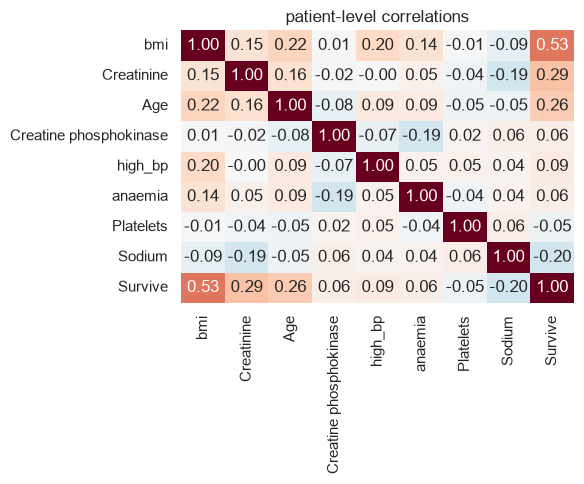

In [34]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(patients[numeric + ["Survive"]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=ax, cbar=False)
ax.set_title("patient-level correlations")
plt.tight_layout(); plt.show()

BMI at 0.53 is far ahead of everything else, and it had to be built first.
Creatinine, age and sodium follow.

### Are these differences real?

Everything so far is a difference between averages, and with 297 patients some
of those gaps could be chance. So each one gets a test.

Two rules matter here. First, **every test runs at patient level**. Running them
on 15000 rows would treat 50 copies of one person as 50 independent
observations, which inflates every sample size by about 50 and turns noise into
significance. Second, testing twelve things at `p < 0.05` expects roughly one
false positive by chance, so the p-values are corrected with
Benjamini-Hochberg.

Welch's t-test for the numeric columns, since the two groups have unequal sizes
(96 against 201) and unequal variances. Chi-square for the categoricals. Cohen's
d and Cramer's V alongside, because a p-value says whether an effect exists and
an effect size says whether it is worth anything.

In [35]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / pooled

def benjamini_hochberg(pvals):
    # adjusted p-values, written out rather than pulling in statsmodels
    pvals = np.asarray(pvals, float)
    n = len(pvals)
    order = np.argsort(pvals)
    adjusted = np.empty(n)
    ranked = pvals[order] * n / np.arange(1, n + 1)
    adjusted[order] = np.minimum.accumulate(ranked[::-1])[::-1]
    return np.minimum(adjusted, 1.0)

results = []
for c in ["bmi", "Creatinine", "Age", "Sodium", "Creatine phosphokinase", "Platelets"]:
    survived = patients.loc[patients["Survive"] == 1, c].dropna()
    died = patients.loc[patients["Survive"] == 0, c].dropna()
    t, p = stats.ttest_ind(survived, died, equal_var=False)
    results.append({"feature": c, "test": "Welch t", "statistic": t,
                    "p_value": p, "effect_size": cohens_d(survived, died),
                    "effect": "Cohen d"})

for c in ["Ejection Fraction", "Gender", "Smoke", "Diabetes", "anaemia", "high_bp"]:
    table = pd.crosstab(patients[c], patients["Survive"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    cramer_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    results.append({"feature": c, "test": "chi-square", "statistic": chi2,
                    "p_value": p, "effect_size": cramer_v, "effect": "Cramer V"})

tests = pd.DataFrame(results).sort_values("p_value").reset_index(drop=True)
tests["p_adjusted"] = benjamini_hochberg(tests["p_value"])
tests["verdict"] = np.where(tests["p_adjusted"] < 0.05, "significant", "no evidence")
tests.round(4)

,feature,test,statistic,p_value,effect_size,effect,p_adjusted,verdict
0,bmi,Welch t,11.0529,0.0000,1.3328,Cohen d,0.0000,significant
1,Age,Welch t,4.1913,0.0000,0.5620,Cohen d,0.0003,significant
2,Creatinine,Welch t,4.1488,0.0001,0.6550,Cohen d,0.0003,significant
3,Sodium,Welch t,-3.1609,0.0019,-0.4239,Cohen d,0.0057,significant
4,high_bp,chi-square,1.8423,0.1747,0.0788,Cramer V,0.3872,no evidence
5,Ejection Fraction,chi-square,3.2839,0.1936,0.1052,Cramer V,0.3872,no evidence
6,anaemia,chi-square,0.9061,0.3412,0.0552,Cramer V,0.5324,no evidence
7,Creatine phosphokinase,Welch t,0.9029,0.3683,0.1341,Cohen d,0.5324,no evidence
8,Platelets,Welch t,-0.8448,0.3993,-0.1050,Cohen d,0.5324,no evidence
9,Smoke,chi-square,0.0198,0.8881,0.0082,Cramer V,1.0000,no evidence


Four features survive correction, and they are the four the correlations already
pointed at: `bmi` (`d = 1.33`, a large effect), `Age` (0.56), `Creatinine`
(0.66) and `Sodium` (-0.42). BMI's p-value is `1.7e-22`, which is not a close
call.

**Nothing else clears the bar.** Two of those non-results are worth stating
plainly, because they correct what the averages seemed to say.

`Ejection Fraction` looked like the one clean categorical split, 0.34 surviving
at `Low` against 0.20 at `Normal`. Tested, it is `p = 0.19`, adjusted to 0.39,
with a Cramer's V of 0.11. The reason is visible in the group sizes: 261 of the
297 patients are `Low` and only 35 are `Normal`, so the comparison rests on 35
people. The difference may be real, but this dataset cannot show it. It is kept
as a feature, and the trained forest does rank it last.

`Creatine phosphokinase` fails the t-test at `p = 0.37` yet ranks third by
importance in the final model. That is not a contradiction, it is the t-test
being the wrong instrument: it compares two means, and CPK's relationship with
survival has no direction (0.23, 0.42, 0.31, 0.39, 0.27 across the five bands).
The means are equal while the relationship exists. A tree can use a shape that a
difference in means cannot see.

The lesson in both directions: a p-value answers one narrow question, and it is
not the same question the model is answering.

### A confidence interval on the headline number

In [36]:
r, p = stats.pearsonr(patients["bmi"], patients["Survive"])
n = len(patients)
z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
lo, hi = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
print(f"bmi correlation with survival, n = {n} patients")
print(f"  r = {r:.3f}   95% CI [{lo:.3f}, {hi:.3f}]   p = {p:.2e}")

bmi correlation with survival, n = 297 patients
  r = 0.530   95% CI [0.443, 0.607]   p = 6.13e-23


The interval runs 0.44 to 0.61 and nowhere near zero, so BMI being the strongest
feature is not an artefact of this particular sample.

### And the decoy, tested

`Favorite color` is redrawn on every row, so it has no patient-level value to
test and the only option is a row-level test. That works in its favour as
evidence: 15000 rows give the test about fifty times more power than it deserves,
and it still finds nothing.

In [37]:
table = pd.crosstab(raw["Favorite color"], df["Survive"])
chi2, p, dof, _ = stats.chi2_contingency(table)
print(f"chi-square on all 15000 rows: chi2 = {chi2:.3f}, dof = {dof}, p = {p:.3f}")

chi-square on all 15000 rows: chi2 = 7.024, dof = 5, p = 0.219


`p = 0.219` with the sample size inflated fifty-fold. Dropped.

Now the categorical breakdowns behind the tests above.

In [38]:
for c in ["Ejection Fraction", "Gender", "Smoke", "Diabetes"]:
    print(patients.groupby(c)["Survive"].agg(["mean", "count"]).round(3).to_string())
    print()

                    mean  count
Ejection Fraction              
High               0.000      1
Low                0.341    261
Normal             0.200     35

         mean  count
Gender              
Female  0.327    104
Male    0.321    193

        mean  count
Smoke              
No     0.328    201
Yes    0.312     96

           mean  count
Diabetes              
Diabetes  0.320    125
Normal    0.326    172



`Ejection Fraction` shows the widest spread of the four, 0.34 at `Low` against
0.20 at `Normal`, with the single `High` patient not surviving, but the test
above says 35 `Normal` patients are not enough to call it. `Gender` (0.327
against 0.321), `Smoke` (0.328 against 0.313) and `Diabetes` (0.326 against
0.320) are flat to three decimal places and test at `p = 1.00`, `0.89` and
`1.00`.

All four are kept anyway. They are genuine clinical variables rather than
planted noise, "no evidence of an effect" is not the same as "no effect", and
dropping them moves grouped cross-validated AUC by less than the fold-to-fold
spread in either direction. The trained model ranks all four last, which is the
honest place for them.

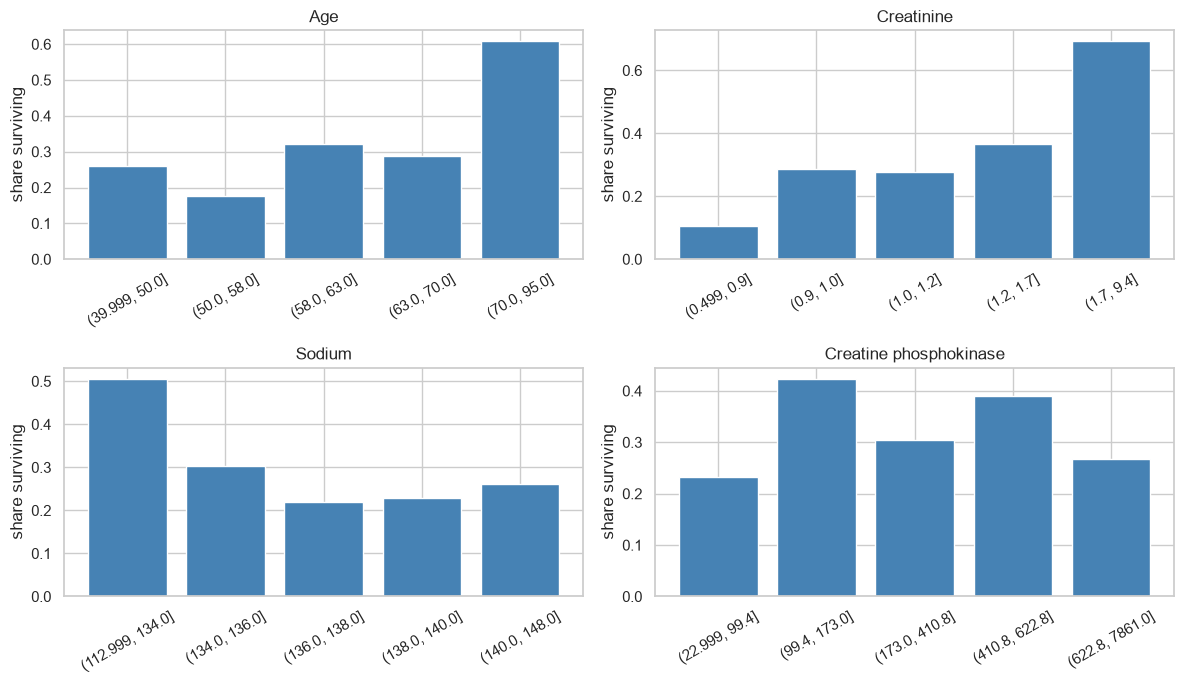

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, c in zip(axes.ravel(), ["Age", "Creatinine", "Sodium", "Creatine phosphokinase"]):
    band = pd.qcut(patients[c], 5, duplicates="drop")
    rate = patients.groupby(band, observed=True)["Survive"].mean()
    ax.bar([str(i) for i in rate.index], rate.values, color="steelblue")
    ax.set_title(c); ax.set_ylabel("share surviving")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

Creatinine rises steadily. Age dips in the fifties before climbing, and
creatine phosphokinase has no direction at all. Two more features a straight
line cannot follow.

### A note on the direction of the label

`Ejection Fraction` low, creatinine high, sodium low and age high all point at
`Survive = 1` here. Clinically those are the markers of a worse outcome, and
this looks like the well known heart-failure records with the outcome column
renamed rather than reversed. Nothing in the file settles it, so the brief is
taken at its word (`1 = Yes`) throughout. If the label is in fact the death
event, every model and every number below is unchanged and only the word
"survived" has to be swapped for "died".

## 9. Decisions

| column | decision | reason |
|---|---|---|
| `ID` | dropped | 885 codes shared by unrelated patients, one mangled to `8.46E+65` |
| `Survive` | target | `No`/`Yes` folded into `0`/`1` |
| `Gender` | kept | constant per patient, but 0.327 against 0.321 |
| `Smoke` | kept, case fixed | `YES`/`NO` folded in. 0.328 against 0.313 |
| `Diabetes` | kept, labels merged | `Pre-diabetes` and `Diabetes` are one condition. 0.326 against 0.320 |
| `Age` | kept, sign fixed | 430 negative values are sign errors. correlation 0.26 |
| `Ejection Fraction` | kept, labels merged | `L`/`N` folded into `Low`/`Normal`. 0.34 / 0.20 / 0.00 |
| `Sodium` | kept | correlation -0.20 |
| `Creatinine` | kept | correlation 0.29. 499 gaps, median filled after the split, no indicator |
| `Platelets` | kept | correlation -0.05 |
| `Creatine phosphokinase` | kept | correlation 0.06, no direction |
| `Blood Pressure` | used, then dropped | two bands per patient, folded into `high_bp` |
| `Hemoglobin` | used, then dropped | two bands per patient, folded into `anaemia` |
| `Height` | used, then dropped | uniform noise alone, needed for `bmi` |
| `Weight` | used, then dropped | folded into `bmi` |
| `Favorite color` | dropped | uniform, flat, redrawn inside every patient |
| `bmi` | created | `Weight / (Height/100)^2`. strongest feature at 0.53 |
| `anaemia` | created | `Hemoglobin < 12` |
| `high_bp` | created | `Blood Pressure >= 120` |
| `patient_key` | created, then dropped | `Age|Sodium|Platelets|CPK`. splits the data, predicts nothing |